# Heart disease: structure, data quality, and exploratory analysis

This notebook audits `data/raw/heart_disease_uci.csv`, then explores distributions,
potential outliers, class balance, and differences across the four recorded sources.
Run the cells in order with the project's `.venv` kernel. Dependencies: pandas, NumPy,
Matplotlib, and IPython; no downloads are needed to run the analysis.

Variable meanings and the binary target convention follow the
[UCI Heart Disease documentation](https://archive.ics.uci.edu/dataset/45/heart%2Bdisease).



In [1]:
from pathlib import Path
import csv
import hashlib
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

%matplotlib inline
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 40)
pd.set_option('display.precision', 3)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False})

# Works when launched from the project root or notebooks directory.
data_path = next((parent / 'data/raw/heart_disease_uci.csv'
                  for parent in [Path.cwd(), *Path.cwd().parents]
                  if (parent / 'data/raw/heart_disease_uci.csv').is_file()), None)
if data_path is None:
    raise FileNotFoundError('Run this notebook from inside the VitalPipe project.')
print('CSV:', data_path)
raw_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
print('SHA-256:', raw_sha256)
print(f'Python {platform.python_version()} | pandas {pd.__version__} | '
      f'NumPy {np.__version__} | Matplotlib {matplotlib.__version__}')


CSV: C:\Users\Owner\Desktop\Programming work\VitalPipe-1\data\raw\heart_disease_uci.csv
SHA-256: 574f2fa2b43012fa25fca4fcdb36bd7c6bccdd0af4242f6c0e4c8633c5a072ae
Python 3.14.0 | pandas 3.0.6 | NumPy 2.5.3 | Matplotlib 3.11.2


## 1. File structure and data dictionary

Check CSV row widths and header integrity before pandas can rename duplicate headers
or infer types. Record physical line numbers for malformed records. Empty and common
missing-value tokens are counted separately from numeric or category errors.


In [2]:
EXPECTED_COLUMNS = ['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol',
                    'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope',
                    'ca', 'thal', 'num']
csv_issues = []
record_count = 0
try:
    with data_path.open(encoding='utf-8-sig', newline='') as handle:
        reader = csv.reader(handle, strict=True)
        header = next(reader)
        for record in reader:
            record_count += 1
            if len(record) != len(header):
                csv_issues.append({'line': reader.line_num,
                                   'fields': len(record), 'expected': len(header)})
except csv.Error as error:
    csv_issues.append({'line': reader.line_num, 'error': str(error)})

file_checks = pd.Series({
    'CSV records': record_count,
    'Header fields': len(header),
    'Duplicate header names': len(header) - len(set(header)),
    'Malformed records': len(csv_issues),
    'Expected ordered schema': header == EXPECTED_COLUMNS,
}, name='result')
display(file_checks.to_frame())
display(pd.DataFrame(csv_issues))
assert not csv_issues and header == EXPECTED_COLUMNS, 'Resolve CSV/schema errors first.'

raw = pd.read_csv(data_path, dtype='string', keep_default_na=False)
tokens = raw.apply(lambda column: column.str.strip())
MISSING_TOKENS = {'', '?', 'na', 'n/a', 'nan', 'null', 'none'}
missing_mask = tokens.apply(lambda column: column.str.lower().isin(MISSING_TOKENS))
tokens = tokens.mask(missing_mask)
assert len(raw) == record_count
display(raw.head())
print(f'{len(raw):,} rows × {raw.shape[1]} columns')


,result
CSV records,920
Header fields,16
Duplicate header names,0
Malformed records,0
Expected ordered schema,True


""


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145,233,TRUE,lv hypertrophy,150,FALSE,2.3,downsloping,0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160,286,FALSE,lv hypertrophy,108,TRUE,1.5,flat,3,normal,2
2,3,67,Male,Cleveland,asymptomatic,120,229,FALSE,lv hypertrophy,129,TRUE,2.6,flat,2,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130,250,FALSE,normal,187,FALSE,3.5,downsloping,0,normal,0
4,5,41,Female,Cleveland,atypical angina,130,204,FALSE,lv hypertrophy,172,FALSE,1.4,upsloping,0,normal,0


920 rows × 16 columns


In [3]:
dictionary = pd.DataFrame([
    ('id', 'identifier', 'Local row ID; exclude from predictors'),
    ('dataset', 'source', 'Recorded contributing source'),
    ('age', 'numeric / integer', 'Age (years)'),
    ('sex', 'categorical', 'Recorded sex'),
    ('cp', 'categorical', 'Chest-pain category'),
    ('trestbps', 'numeric', 'Resting blood pressure (mm Hg)'),
    ('chol', 'numeric', 'Serum cholesterol (mg/dL)'),
    ('fbs', 'boolean', 'Fasting glucose above 120 mg/dL'),
    ('restecg', 'categorical', 'Resting ECG category'),
    ('thalch', 'numeric', 'Maximum achieved heart rate'),
    ('exang', 'boolean', 'Exercise-induced angina'),
    ('oldpeak', 'numeric', 'Exercise versus rest ST depression'),
    ('slope', 'categorical', 'Peak-exercise ST slope'),
    ('ca', 'discrete / integer', 'Fluoroscopy vessel count (0–3)'),
    ('thal', 'categorical', 'Thallium-test category'),
    ('num', 'target / integer', 'Recorded diagnosis class (0–4)'),
], columns=['column', 'role/type', 'meaning']).set_index('column')
display(dictionary)


,role/type,meaning
column,,
id,identifier,Local row ID; exclude from predictors
dataset,source,Recorded contributing source
age,numeric / integer,Age (years)
sex,categorical,Recorded sex
cp,categorical,Chest-pain category
trestbps,numeric,Resting blood pressure (mm Hg)
chol,numeric,Serum cholesterol (mg/dL)
fbs,boolean,Fasting glucose above 120 mg/dL
restecg,categorical,Resting ECG category


## 2. Malformed tokens, valid categories, and numeric consistency

The checks below distinguish missing tokens from parse failures, nonfinite values,
fractional integer fields, invalid category labels, and domain violations. Positive
age, blood pressure, cholesterol, and heart rate are basic consistency requirements,
not clinical reference intervals. Extreme positive measurements require review rather
than automatic rejection. Negative `oldpeak` is reported separately and retained.

The CSV's spelling `reversable defect` is explicitly accepted and preserved.


In [4]:
NUMERIC = ['id', 'age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca', 'num']
INTEGER = ['id', 'age', 'ca', 'num']
CONTINUOUS = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
CATEGORIES = {
    'sex': ['Female', 'Male'],
    'dataset': ['Cleveland', 'Hungary', 'Switzerland', 'VA Long Beach'],
    'cp': ['typical angina', 'atypical angina', 'non-anginal', 'asymptomatic'],
    'restecg': ['normal', 'st-t abnormality', 'lv hypertrophy'],
    'slope': ['upsloping', 'flat', 'downsloping'],
    'thal': ['normal', 'fixed defect', 'reversable defect'],
}
BOOLEAN = ['fbs', 'exang']
df = tokens.copy()
flags = {}
for column in NUMERIC:
    numeric = pd.to_numeric(tokens[column], errors='coerce').astype('float64')
    flags[(column, 'unparseable numeric token')] = tokens[column].notna() & numeric.isna()
    flags[(column, 'nonfinite numeric value')] = numeric.notna() & ~np.isfinite(numeric)
    if column in INTEGER:
        flags[(column, 'fractional integer')] = (numeric.notna() & np.isfinite(numeric)
                                               & numeric.mod(1).ne(0))
    df[column] = numeric

for column, allowed in CATEGORIES.items():
    flags[(column, 'unknown category')] = tokens[column].notna() & ~tokens[column].isin(allowed)
for column in BOOLEAN:
    values = tokens[column].str.upper()
    flags[(column, 'unknown boolean token')] = values.notna() & ~values.isin(['TRUE', 'FALSE'])
    df[column] = values.map({'TRUE': True, 'FALSE': False}).astype('boolean')
for column in ['id', 'age', 'trestbps', 'chol', 'thalch']:
    flags[(column, 'nonpositive value')] = df[column].notna() & df[column].le(0)
for column, allowed in {'ca': [0, 1, 2, 3], 'num': [0, 1, 2, 3, 4]}.items():
    flags[(column, 'outside allowed codes')] = df[column].notna() & ~df[column].isin(allowed)
for column in ['id', 'age', 'sex', 'dataset', 'cp', 'num']:
    flags[(column, 'missing required value')] = tokens[column].isna()

audit_rows = []
for column in EXPECTED_COLUMNS:
    column_flags = {rule: mask for (col, rule), mask in flags.items() if col == column}
    audit_rows.append({
        'column': column, 'dtype': str(df[column].dtype),
        'missing_tokens': int(missing_mask[column].sum()),
        'surrounding_whitespace': int(raw[column].ne(raw[column].str.strip()).sum()),
        'observed_unique': int(tokens[column].nunique()),
        'flagged_cells': int(pd.concat(column_flags, axis=1).any(axis=1).sum()),
    })
quality_audit = pd.DataFrame(audit_rows).set_index('column')
quality_audit['missing_pct'] = quality_audit['missing_tokens'].div(len(df)).mul(100)
display(quality_audit)

issue_parts = []
for (column, rule), mask in flags.items():
    mask = mask.fillna(False)
    if mask.any():
        part = raw.loc[mask, ['id', 'dataset']].copy()
        part.insert(0, 'csv_record', part.index + 2)
        part['column'], part['rule'] = column, rule
        part['raw_value'] = raw.loc[mask, column]
        issue_parts.append(part)
issues = (pd.concat(issue_parts, ignore_index=True) if issue_parts else
          pd.DataFrame(columns=['csv_record', 'id', 'dataset', 'column', 'rule', 'raw_value']))
display(issues.groupby(['column', 'rule']).size().rename('cells').to_frame())
display(issues.head(15))
print('CSV record numbers include the header; raw is unchanged.')
display(df.loc[df['oldpeak'].lt(0), ['id', 'dataset', 'oldpeak', 'num']])


,dtype,missing_tokens,surrounding_whitespace,observed_unique,flagged_cells,missing_pct
column,,,,,,
id,float64,0,0,920,0,0.000
age,float64,0,0,50,0,0.000
sex,string,0,0,2,0,0.000
dataset,string,0,0,4,0,0.000
cp,string,0,0,4,0,0.000
trestbps,float64,59,0,61,1,6.413
chol,float64,30,0,217,172,3.261
fbs,boolean,90,0,2,0,9.783
restecg,string,2,0,3,0,0.217


,,cells
column,rule,
chol,nonpositive value,172
trestbps,nonpositive value,1


,csv_record,id,dataset,column,rule,raw_value
0,755,754,VA Long Beach,trestbps,nonpositive value,0
1,599,598,Switzerland,chol,nonpositive value,0
2,600,599,Switzerland,chol,nonpositive value,0
3,601,600,Switzerland,chol,nonpositive value,0
4,602,601,Switzerland,chol,nonpositive value,0
5,603,602,Switzerland,chol,nonpositive value,0
6,604,603,Switzerland,chol,nonpositive value,0
7,605,604,Switzerland,chol,nonpositive value,0
8,606,605,Switzerland,chol,nonpositive value,0
9,607,606,Switzerland,chol,nonpositive value,0


CSV record numbers include the header; raw is unchanged.


,id,dataset,oldpeak,num
603,604.0,Switzerland,-1.1,0.0
609,610.0,Switzerland,-1.5,1.0
614,615.0,Switzerland,-0.1,0.0
615,616.0,Switzerland,-2.6,1.0
629,630.0,Switzerland,-0.7,2.0
653,654.0,Switzerland,-2.0,2.0
655,656.0,Switzerland,-1.0,1.0
656,657.0,Switzerland,-1.0,2.0
691,692.0,Switzerland,-0.8,1.0
694,695.0,Switzerland,-0.5,1.0


## 3. Duplicate records and conflicting labels

Unique IDs can hide repeated records. Compare literal rows, IDs, rows without ID,
and predictor profiles without ID or target. Also compare profiles without source.
Matching profiles are review candidates: they do not prove the same patient, especially
with many missing fields. Counts marked "extra" exclude the first occurrence.


In [5]:
record_columns = [c for c in EXPECTED_COLUMNS if c != 'id']
patient_fields = [c for c in EXPECTED_COLUMNS if c not in ['id', 'dataset', 'num']]
profile_columns = ['dataset', *patient_fields]
duplicate_summary = pd.Series({
    'Literal exact rows: extra': int(raw.duplicated().sum()),
    'Repeated nonmissing IDs: extra': int(df.loc[df.id.notna(), 'id'].duplicated().sum()),
    'Same record excluding ID: extra': int(df.duplicated(record_columns).sum()),
    'Same record excluding ID/source: extra': int(df.duplicated(patient_fields + ['num']).sum()),
    'Same predictor profile within source: extra': int(df.duplicated(profile_columns).sum()),
    'Same predictor profile across all sources: extra': int(df.duplicated(patient_fields).sum()),
}, name='count')
display(duplicate_summary.to_frame())
duplicate_records = df.loc[df.duplicated(record_columns, keep=False)].sort_values(record_columns)
display(duplicate_records)

conflicts = df.groupby(profile_columns, dropna=False)['num'].transform('nunique').gt(1)
cross_source_conflicts = df.groupby(patient_fields, dropna=False)['num'].transform('nunique').gt(1)
print('Rows with conflicting labels in an identical within-source profile:', int(conflicts.sum()))
print('Rows with conflicting labels in an identical profile ignoring source:',
      int(cross_source_conflicts.sum()))
display(df.loc[conflicts | cross_source_conflicts])


,count
Literal exact rows: extra,0
Repeated nonmissing IDs: extra,0
Same record excluding ID: extra,2
Same record excluding ID/source: extra,2
Same predictor profile within source: extra,2
Same predictor profile across all sources: extra,2


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
404,405.0,49.0,Female,Hungary,atypical angina,110.0,NaN,False,normal,160.0,False,0.0,<NA>,NaN,<NA>,0.0
405,406.0,49.0,Female,Hungary,atypical angina,110.0,NaN,False,normal,160.0,False,0.0,<NA>,NaN,<NA>,0.0
859,860.0,58.0,Male,VA Long Beach,non-anginal,150.0,219.0,False,st-t abnormality,118.0,True,0.0,<NA>,NaN,<NA>,2.0
907,908.0,58.0,Male,VA Long Beach,non-anginal,150.0,219.0,False,st-t abnormality,118.0,True,0.0,<NA>,NaN,<NA>,2.0


Rows with conflicting labels in an identical within-source profile: 0
Rows with conflicting labels in an identical profile ignoring source: 0


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num


## 4. Missingness and suspect zero measurements

Null counts alone miss placeholder-like zeros. `analysis_df` masks flagged numeric
and categorical values, including nonpositive measurements, while retaining every row.
For cholesterol, zero is treated as an unavailable measurement for EDA; the CSV does
not document how these zeros arose. Compare raw and analysis missingness explicitly.
Invalid target codes become unknown rather than being assigned a disease label.


,raw_missing_n,analysis_unavailable_n,raw_missing_pct,analysis_unavailable_pct
ca,611,611,66.413,66.413
thal,486,486,52.826,52.826
slope,309,309,33.587,33.587
chol,30,202,3.261,21.957
fbs,90,90,9.783,9.783
oldpeak,62,62,6.739,6.739
trestbps,59,60,6.413,6.522
thalch,55,55,5.978,5.978
exang,55,55,5.978,5.978
restecg,2,2,0.217,0.217


,trestbps,chol,thalch
dataset,,,
Cleveland,0,0,0
Hungary,0,0,0
Switzerland,0,123,0
VA Long Beach,1,49,0


Rows complete on all 13 raw predictors: 299
Rows complete on all 13 analysis predictors: 299


,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal
dataset,,,,,,,,,,,,,
Cleveland,0.0,0.0,0.0,0.000,0.00,0.000,0.000,0.000,0.000,0.000,0.329,1.645,0.987
Hungary,0.0,0.0,0.0,0.341,7.85,2.730,0.341,0.341,0.341,0.000,64.505,98.976,90.444
Switzerland,0.0,0.0,0.0,1.626,100.00,60.976,0.813,0.813,0.813,4.878,13.821,95.935,42.276
VA Long Beach,0.0,0.0,0.0,28.500,28.00,3.500,0.000,26.500,26.500,28.000,51.000,99.000,83.000


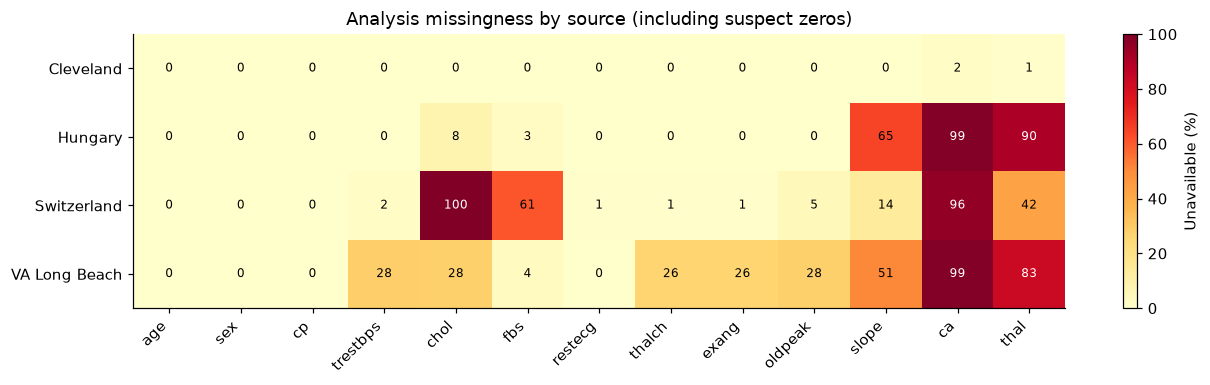

In [6]:
analysis_df = df.copy(deep=True)
for (column, rule), mask in flags.items():
    analysis_df.loc[mask.fillna(False), column] = pd.NA if column not in NUMERIC else np.nan
target_valid = analysis_df['num'].isin([0, 1, 2, 3, 4])
analysis_df['disease_present'] = analysis_df['num'].gt(0).where(target_valid).astype('boolean')
SOURCES = CATEGORIES['dataset']
PREDICTORS = [c for c in EXPECTED_COLUMNS if c not in ['id', 'dataset', 'num']]

missing_summary = pd.DataFrame({
    'raw_missing_n': missing_mask.sum(),
    'analysis_unavailable_n': analysis_df[EXPECTED_COLUMNS].isna().sum(),
})
missing_summary['raw_missing_pct'] = missing_summary.raw_missing_n.div(len(df)).mul(100)
missing_summary['analysis_unavailable_pct'] = missing_summary.analysis_unavailable_n.div(len(df)).mul(100)
display(missing_summary.sort_values('analysis_unavailable_n', ascending=False))

zero_by_source = df.groupby('dataset')[['trestbps', 'chol', 'thalch']].agg(lambda s: s.eq(0).sum())
display(zero_by_source.reindex(SOURCES))
print('Rows complete on all 13 raw predictors:', int(df[PREDICTORS].notna().all(axis=1).sum()))
print('Rows complete on all 13 analysis predictors:', int(analysis_df[PREDICTORS].notna().all(axis=1).sum()))

missing_by_source = (analysis_df[PREDICTORS].isna().groupby(analysis_df.dataset)
                     .mean().reindex(SOURCES).mul(100))
display(missing_by_source)
fig, ax = plt.subplots(figsize=(12, 3.6))
heat = ax.imshow(missing_by_source, vmin=0, vmax=100, cmap='YlOrRd', aspect='auto')
ax.set_xticks(range(len(PREDICTORS)), PREDICTORS, rotation=45, ha='right')
ax.set_yticks(range(len(SOURCES)), SOURCES)
for row in range(len(SOURCES)):
    for col in range(len(PREDICTORS)):
        value = missing_by_source.iloc[row, col]
        ax.text(col, row, f'{value:.0f}', ha='center', va='center', fontsize=8,
                color='white' if value > 65 else 'black')
fig.colorbar(heat, ax=ax, label='Unavailable (%)')
ax.set_title('Analysis missingness by source (including suspect zeros)')
fig.tight_layout()
plt.show()


,rows
unavailable_predictors,
0,299
1,26
2,212
3,231
4,92
5,4
6,2
7,43
8,11


,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal
disease_present,,,,,,,,,,,,,
False,0.0,0.0,0.0,4.866,9.489,3.406,0.000,4.866,4.866,5.109,46.959,59.854,54.501
True,0.0,0.0,0.0,7.859,32.024,14.931,0.393,6.876,6.876,8.055,22.790,71.709,51.473


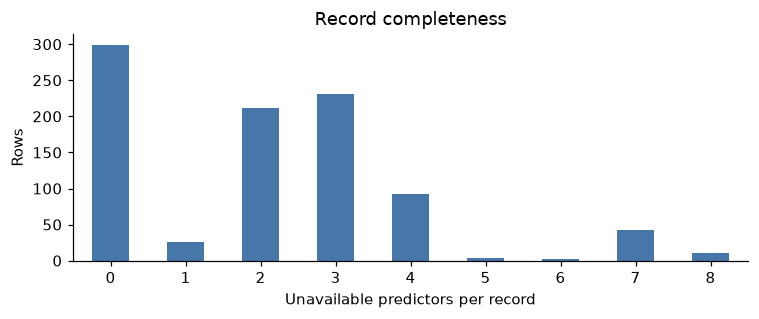

In [7]:
missing_per_row = analysis_df[PREDICTORS].isna().sum(axis=1)
display(missing_per_row.value_counts().sort_index().rename_axis('unavailable_predictors')
        .rename('rows').to_frame())
display(analysis_df[PREDICTORS].isna().groupby(analysis_df['disease_present'])
        .mean().mul(100).rename_axis('disease_present'))
fig, ax = plt.subplots(figsize=(7, 3))
missing_per_row.value_counts().sort_index().plot.bar(ax=ax, color='#4776a8')
ax.set(xlabel='Unavailable predictors per record', ylabel='Rows', title='Record completeness')
plt.xticks(rotation=0)
fig.tight_layout()
plt.show()


## 5. Target distribution and class balance

Preserve the five recorded `num` classes. For the additional binary view,
`num == 0` means absence and `num > 0` means presence, following
[UCI's convention](https://archive.ics.uci.edu/dataset/45/heart%2Bdisease).
Percentages use valid labels as their denominator; unknown targets are counted separately.
Rates describe this dataset, not population prevalence.


,rows,pct_valid_labels
num,,
0,411,44.674
1,265,28.804
2,109,11.848
3,107,11.630
4,28,3.043


,rows,pct_valid_labels
Absent (0),411,44.674
Present (1–4),509,55.326


Unknown/invalid labels: 0
Binary majority-class baseline: 55.3%
Five-class majority-class baseline: 44.7%


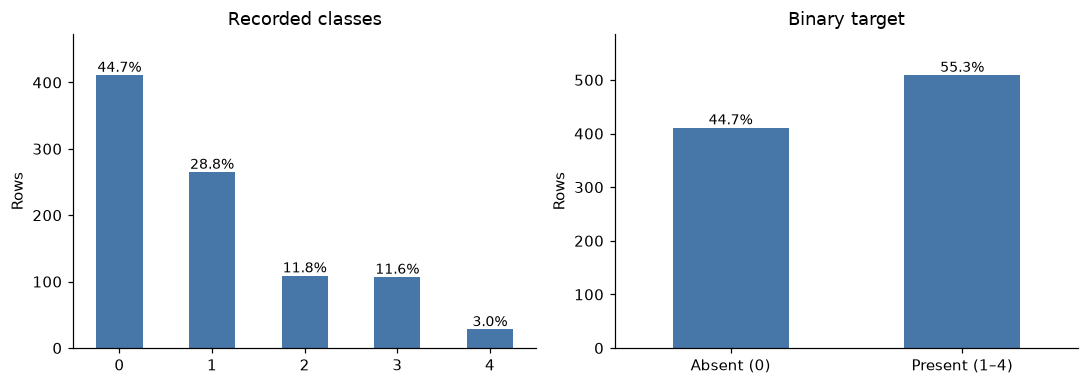

num,0,1,2,3,4
dataset,,,,,
Cleveland,165,55,36,35,13
Hungary,187,106,0,0,0
Switzerland,8,48,32,30,5
VA Long Beach,51,56,41,42,10


num,0,1,2,3,4
dataset,,,,,
Cleveland,54.276,18.092,11.842,11.513,4.276
Hungary,63.823,36.177,0.000,0.000,0.000
Switzerland,6.504,39.024,26.016,24.390,4.065
VA Long Beach,25.500,28.000,20.500,21.000,5.000


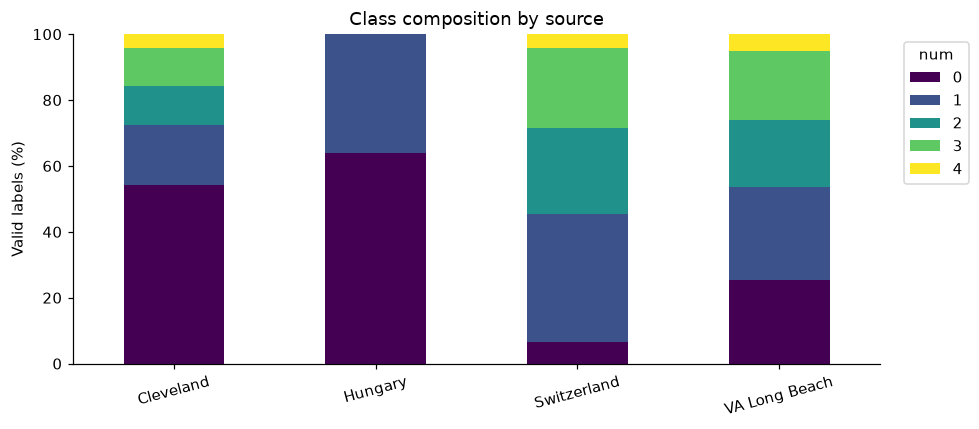

In [8]:
class_counts = analysis_df['num'].value_counts().reindex(range(5), fill_value=0)
class_balance = pd.DataFrame({'rows': class_counts,
                             'pct_valid_labels': class_counts.div(class_counts.sum()).mul(100)})
class_balance.index.name = 'num'
binary_counts = analysis_df['disease_present'].value_counts().reindex([False, True], fill_value=0)
binary_balance = pd.DataFrame({'rows': binary_counts,
                              'pct_valid_labels': binary_counts.div(binary_counts.sum()).mul(100)})
binary_balance.index = ['Absent (0)', 'Present (1–4)']
display(class_balance)
display(binary_balance)
print('Unknown/invalid labels:', int((~target_valid).sum()))
print(f'Binary majority-class baseline: {binary_counts.max() / binary_counts.sum():.1%}')
print(f'Five-class majority-class baseline: {class_counts.max() / class_counts.sum():.1%}')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, table, title in zip(axes, [class_balance, binary_balance], ['Recorded classes', 'Binary target']):
    table['rows'].plot.bar(ax=ax, color='#4776a8', rot=0)
    ax.set(title=title, ylabel='Rows', xlabel='')
    for bar, pct in zip(ax.patches, table['pct_valid_labels']):
        ax.annotate(f'{pct:.1f}%', (bar.get_x() + bar.get_width()/2, bar.get_height()),
                    ha='center', va='bottom', fontsize=9)
    ax.margins(y=0.15)
fig.tight_layout()
plt.show()

source_classes = pd.crosstab(analysis_df.dataset, analysis_df['num']).reindex(index=SOURCES, columns=range(5), fill_value=0)
source_class_pct = source_classes.div(source_classes.sum(axis=1), axis=0).mul(100)
display(source_classes)
display(source_class_pct)
fig, ax = plt.subplots(figsize=(9, 4))
source_class_pct.plot.bar(stacked=True, ax=ax, colormap='viridis', rot=15)
ax.set(ylabel='Valid labels (%)', xlabel='', title='Class composition by source', ylim=(0, 100))
ax.legend(title='num', bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout()
plt.show()


## 6. Numeric distributions and the effect of suspect values

Summaries and histograms use observed values in `analysis_df`; each feature can have a
different denominator. `ca` is a discrete count and is plotted with categories later.
IDs, source codes, and `num` are excluded from continuous-variable summaries.


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew
age,920.0,53.511,9.425,28.0,32.000,37.00,47.0,54.0,60.00,68.00,74.00,77.0,-0.196
trestbps,860.0,132.286,18.536,80.0,95.000,105.95,120.0,130.0,140.00,160.20,180.00,200.0,0.630
chol,718.0,246.833,58.527,85.0,133.190,168.00,210.0,239.5,276.75,340.15,451.03,603.0,1.315
thalch,865.0,137.546,25.926,60.0,75.560,95.00,120.0,140.0,157.00,178.00,186.36,202.0,-0.211
oldpeak,858.0,0.879,1.091,-2.6,-0.586,0.00,0.0,0.5,1.50,3.00,4.00,6.2,1.041


,raw_chol,positive_chol_only
count,890.000,718.000
mean,199.130,246.833
std,110.781,58.527
min,0.000,85.000
25%,175.000,210.000
50%,223.000,239.500
75%,268.000,276.750
max,603.000,603.000


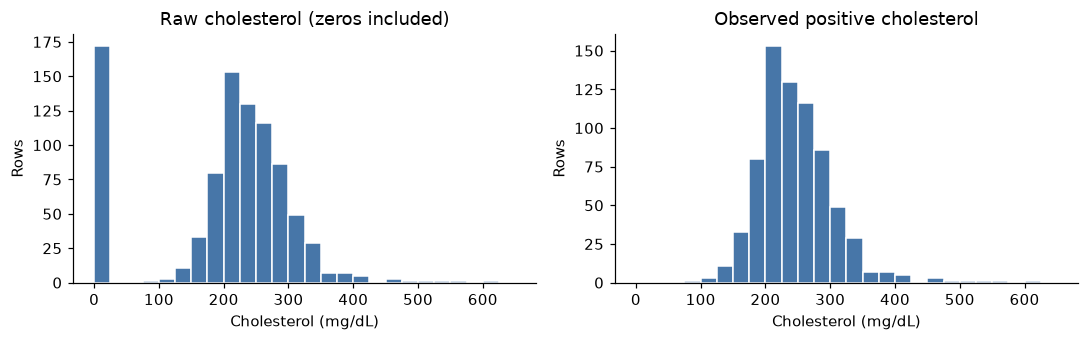

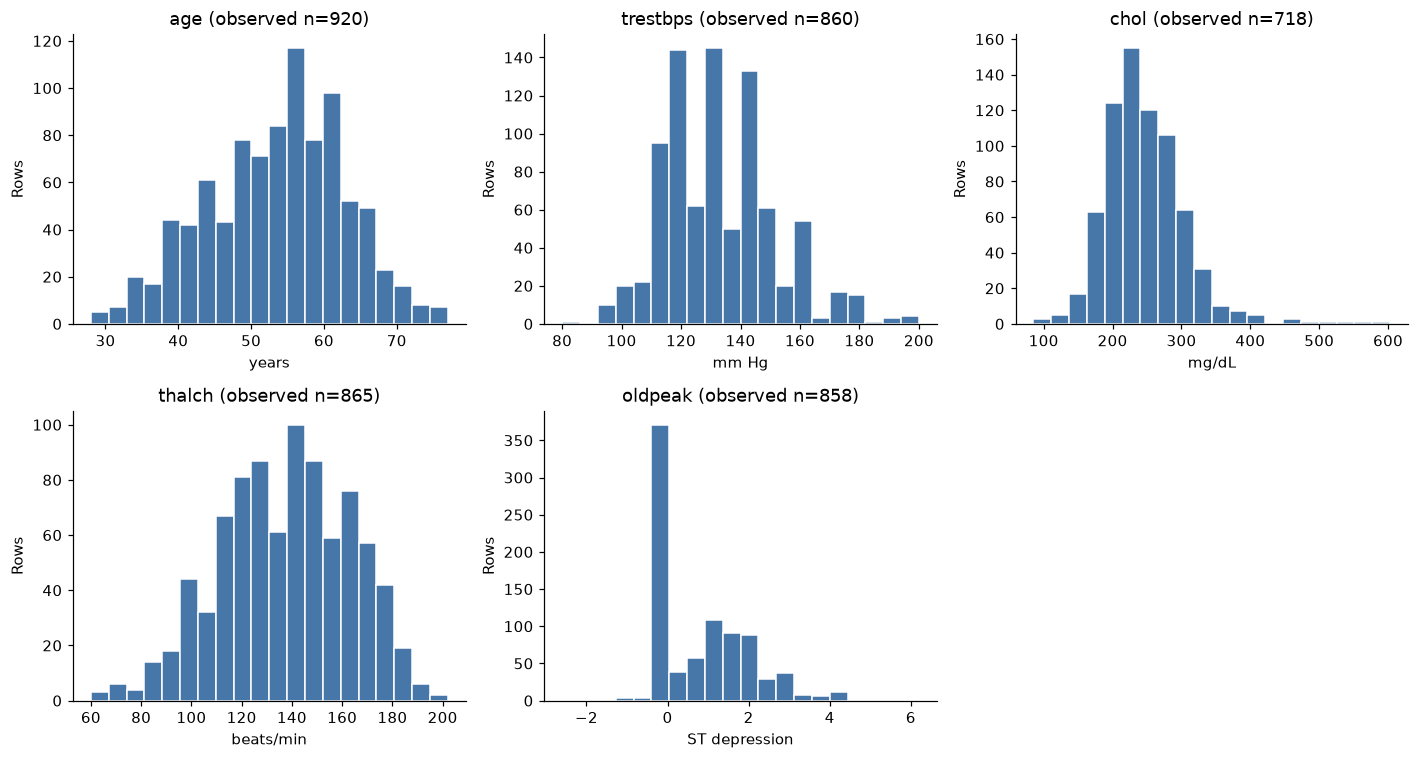

In [9]:
numeric_summary = analysis_df[CONTINUOUS].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
numeric_summary['skew'] = analysis_df[CONTINUOUS].skew()
display(numeric_summary)
display(pd.DataFrame({
    'raw_chol': df.chol.describe(),
    'positive_chol_only': analysis_df.chol.describe(),
}))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharex=True)
for ax, series, title in zip(axes, [df.chol, analysis_df.chol],
                             ['Raw cholesterol (zeros included)', 'Observed positive cholesterol']):
    ax.hist(series.dropna(), bins=np.arange(0, 651, 25), color='#4776a8', edgecolor='white')
    ax.set(title=title, xlabel='Cholesterol (mg/dL)', ylabel='Rows')
fig.tight_layout()
plt.show()

units = {'age': 'years', 'trestbps': 'mm Hg', 'chol': 'mg/dL', 'thalch': 'beats/min', 'oldpeak': 'ST depression'}
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, feature in zip(axes.flat, CONTINUOUS):
    values = analysis_df[feature].dropna()
    ax.hist(values, bins=20, color='#4776a8', edgecolor='white')
    ax.set(title=f'{feature} (observed n={len(values)})', xlabel=units[feature], ylabel='Rows')
axes.flat[-1].set_visible(False)
fig.tight_layout()
plt.show()


## 7. Potential outliers: pooled and within-source checks

Use Tukey fences (`Q1 - 1.5×IQR`, `Q3 + 1.5×IQR`) on the five continuous predictors.
These are distribution-based review flags, not medical cutoffs or reasons to delete
records. Compare pooled flags with fences fitted separately within each source;
source mixtures can change which observations look unusual. No fence is used when
there are fewer than four observations or IQR is zero.


In [10]:
def iqr_audit(frame, source_name):
    rows = []
    masks = {}
    for feature in CONTINUOUS:
        series = frame[feature]
        observed = series.dropna()
        q1, q3 = observed.quantile([.25, .75])
        iqr = q3 - q1
        usable = len(observed) >= 4 and pd.notna(iqr) and iqr > 0
        lower, upper = (q1 - 1.5 * iqr, q3 + 1.5 * iqr) if usable else (np.nan, np.nan)
        mask = (series.lt(lower) | series.gt(upper)) if usable else pd.Series(False, index=frame.index)
        masks[feature] = mask
        rows.append({'source': source_name, 'feature': feature, 'observed_n': len(observed),
                     'q1': q1, 'q3': q3, 'iqr': iqr, 'lower_fence': lower, 'upper_fence': upper,
                     'outlier_n': int(mask.sum()) if usable else np.nan,
                     'outlier_pct_observed': mask.sum() / len(observed) * 100 if usable else np.nan,
                     'status': 'computed' if usable else 'insufficient data / zero IQR'})
    return pd.DataFrame(rows), pd.DataFrame(masks)

pooled_outliers, pooled_flags = iqr_audit(analysis_df, 'All sources')
display(pooled_outliers.set_index('feature'))
source_outlier_tables = []
source_flags = pd.DataFrame(False, index=analysis_df.index, columns=CONTINUOUS)
for source in SOURCES:
    subset = analysis_df.loc[analysis_df.dataset.eq(source)]
    table, masks = iqr_audit(subset, source)
    source_outlier_tables.append(table)
    source_flags.loc[subset.index] = masks
source_outliers = pd.concat(source_outlier_tables, ignore_index=True)
display(source_outliers.set_index(['source', 'feature']))
display(pd.DataFrame({
    'pooled_flags_n': pooled_flags.sum(),
    'within_source_flags_n': source_flags.sum(),
    'different_flag_n': pooled_flags.ne(source_flags).sum(),
}))

outlier_records = analysis_df.loc[pooled_flags.any(axis=1), ['id', 'dataset', *CONTINUOUS, 'num']].copy()
outlier_records['flagged_features'] = pooled_flags.loc[outlier_records.index].apply(
    lambda row: ', '.join(row.index[row]), axis=1)
display(outlier_records.head(20))
print(f'{len(outlier_records)} records have at least one pooled IQR flag; all remain in the analysis.')


,source,observed_n,q1,q3,iqr,lower_fence,upper_fence,outlier_n,outlier_pct_observed,status
feature,,,,,,,,,,
age,All sources,920,47.0,60.00,13.00,27.500,79.500,0,0.000,computed
trestbps,All sources,860,120.0,140.00,20.00,90.000,170.000,27,3.140,computed
chol,All sources,718,210.0,276.75,66.75,109.875,376.875,23,3.203,computed
thalch,All sources,865,120.0,157.00,37.00,64.500,212.500,2,0.231,computed
oldpeak,All sources,858,0.0,1.50,1.50,-2.250,3.750,16,1.865,computed


observed_n      q1      q3    iqr  lower_fence  \
source        feature                                                    
Cleveland     age              304   47.75   61.00  13.25       27.875   
              trestbps         304  120.00  140.00  20.00       90.000   
              chol             304  211.00  275.00  64.00      115.000   
              thalch           304  133.75  166.00  32.25       85.375   
              oldpeak          304    0.00    1.60   1.60       -2.400   
Hungary       age              293   42.00   54.00  12.00       24.000   
              trestbps         292  120.00  140.00  20.00       90.000   
              chol             270  209.25  282.75  73.50       99.000   
              thalch           292  122.00  155.00  33.00       72.500   
              oldpeak          293    0.00    1.00   1.00       -1.500   
Switzerland   age              123   51.00   61.50  10.50       35.250   
              trestbps         121  115.00  145.00  30.00       70.000   
              chol               0     NaN     NaN    NaN          NaN   
              thalch           122  104.25  140.00  35.75       50.625   
              oldpeak          117    0.00    1.50   1.50       -2.250   
VA Long Beach age              200   55.00   64.00   9.00       41.500   
              trestbps         143  120.00  148.00  28.00       78.000   
              chol             144  208.00  271.25  63.25      113.125   
              thalch           147  109.00  140.00  31.00       62.500   
              oldpeak          144    0.00    2.00   2.00       -3.000   

                        upper_fence  outlier_n  outlier_pct_observed  \
source        feature                                                  
Cleveland     age            80.875        0.0                 0.000   
              trestbps      170.000        9.0                 2.961   
              chol          371.000        5.0                 1.645   
              thalch        214.375        1.0                 0.329   
              oldpeak         4.000        5.0                 1.645   
Hungary       age            72.000        0.0                 0.000   
              trestbps      170.000        8.0                 2.740   
              chol          393.000       10.0                 3.704   
              thalch        204.500        0.0                 0.000   
              oldpeak         2.500       11.0                 3.754   
Switzerland   age            77.250        3.0                 2.439   
              trestbps      190.000        2.0                 1.653   
              chol              NaN        NaN                   NaN   
              thalch        193.625        0.0                 0.000   
              oldpeak         3.750        1.0                 0.855   
VA Long Beach age            77.500        7.0                 3.500   
              trestbps      190.000        0.0                 0.000   
              chol          366.125        5.0                 3.472   
              thalch        186.500        0.0                 0.000   
              oldpeak         5.000        0.0                 0.000   

                                              status  
source        feature                                 
Cleveland     age                           computed  
              trestbps                      computed  
              chol                          computed  
              thalch                        computed  
              oldpeak                       computed  
Hungary       age                           computed  
              trestbps                      computed  
              chol                          computed  
              thalch                        computed  
              oldpeak                       computed  
Switzerland   age                           computed  
              trestbps                      computed  
              chol      insufficient dat

,pooled_flags_n,within_source_flags_n,different_flag_n
age,0,10,10
trestbps,27,19,8
chol,23,20,5
thalch,2,1,3
oldpeak,16,17,17


,id,dataset,age,trestbps,chol,thalch,oldpeak,num,flagged_features
14,15.0,Cleveland,52.0,172.0,199.0,162.0,0.5,0.0,trestbps
48,49.0,Cleveland,65.0,140.0,417.0,157.0,0.8,0.0,chol
83,84.0,Cleveland,68.0,180.0,274.0,150.0,1.6,3.0,trestbps
91,92.0,Cleveland,62.0,160.0,164.0,145.0,6.2,3.0,oldpeak
121,122.0,Cleveland,63.0,150.0,407.0,154.0,4.0,4.0,"chol, oldpeak"
123,124.0,Cleveland,55.0,140.0,217.0,111.0,5.6,3.0,oldpeak
126,127.0,Cleveland,56.0,200.0,288.0,133.0,4.0,3.0,"trestbps, oldpeak"
152,153.0,Cleveland,67.0,115.0,564.0,160.0,1.6,0.0,chol
172,173.0,Cleveland,59.0,174.0,249.0,143.0,0.0,1.0,trestbps
173,174.0,Cleveland,62.0,140.0,394.0,157.0,1.2,0.0,chol


64 records have at least one pooled IQR flag; all remain in the analysis.


## 8. Categorical and discrete distributions

Include an explicit missing category so unavailable values remain visible. Counts and
percentages use all rows. Source-specific composition uses each source's row count.


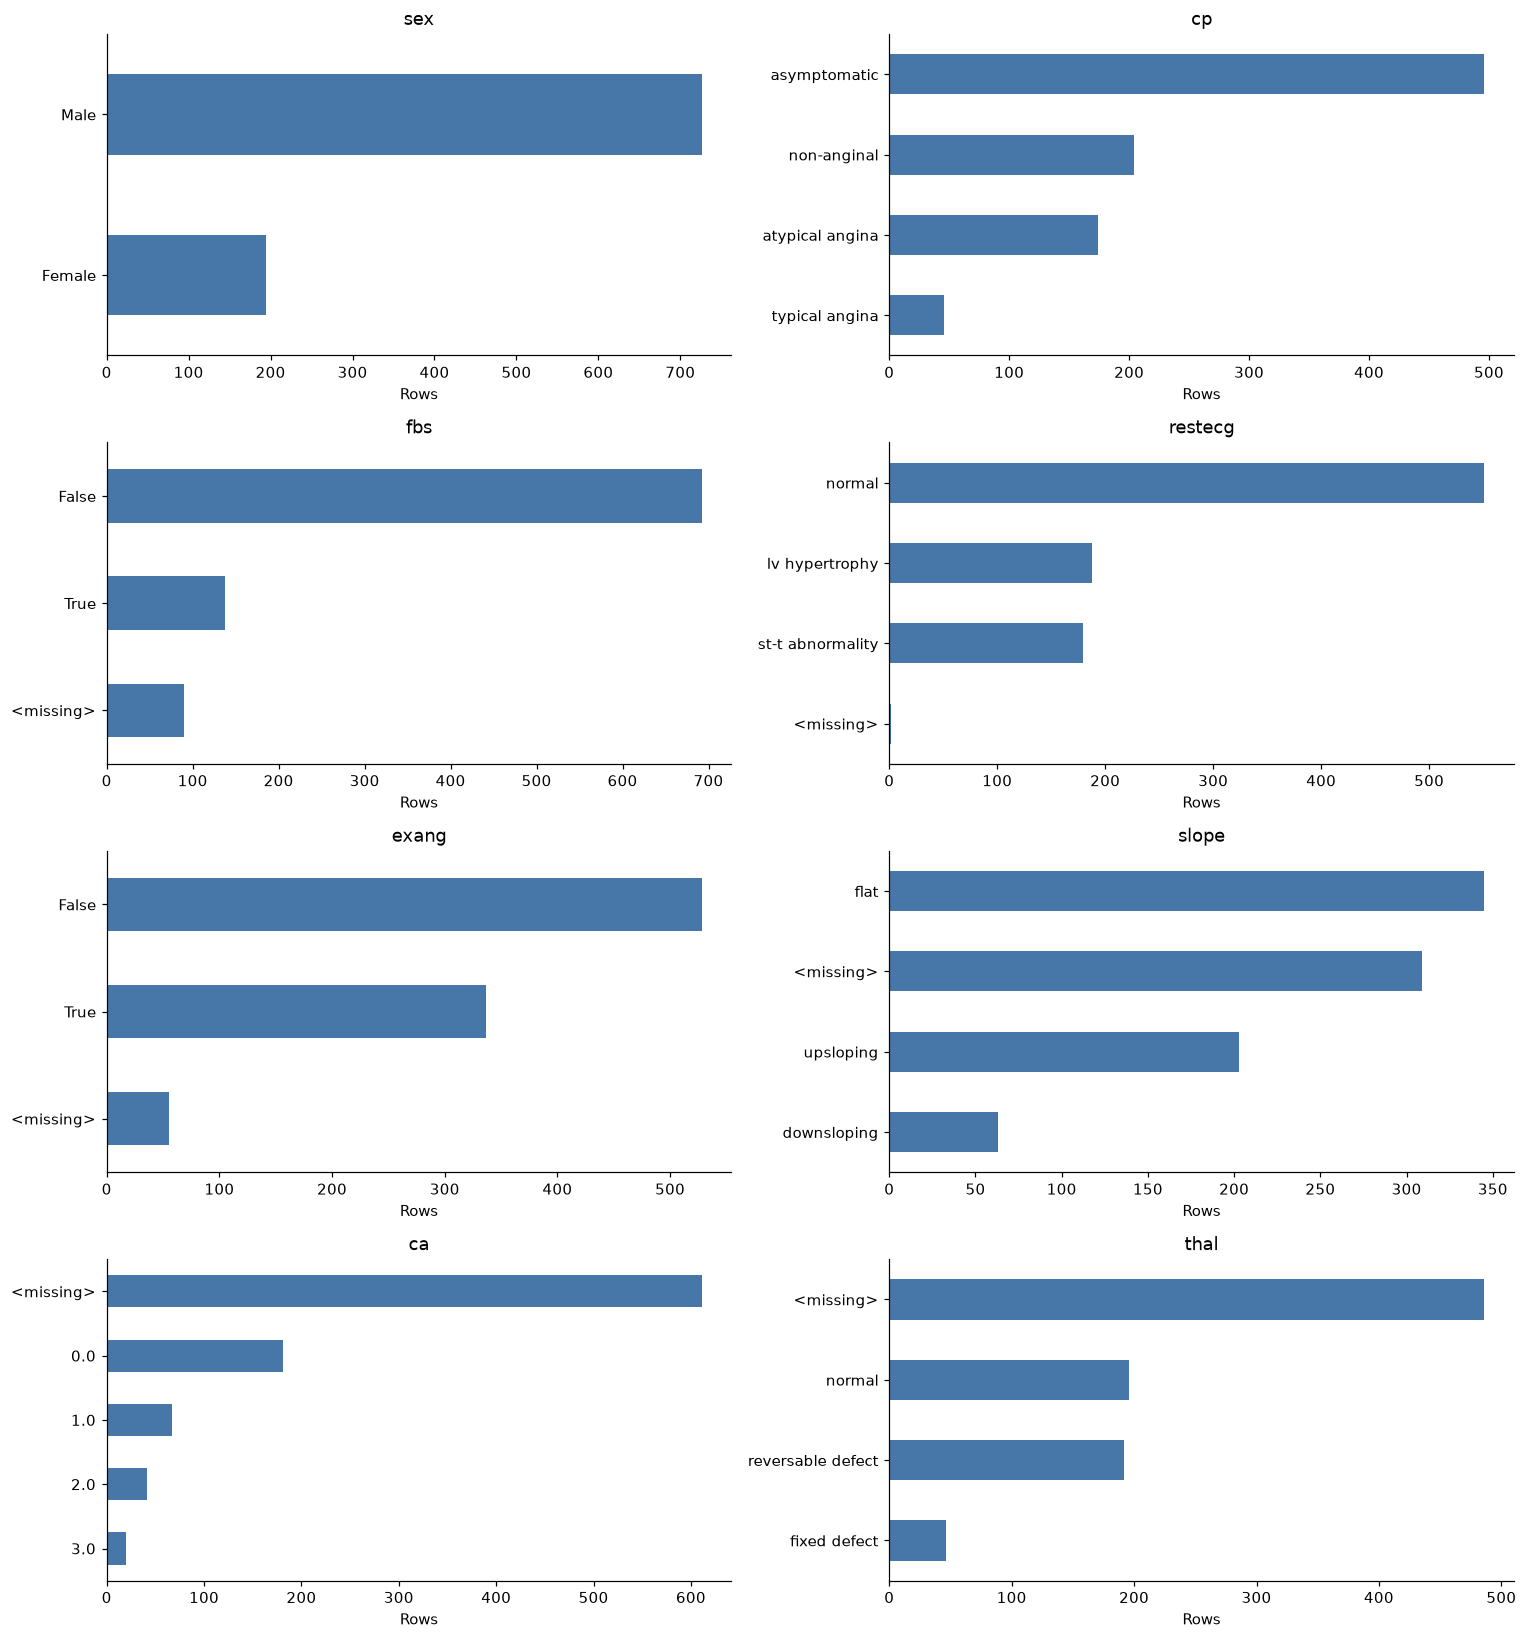

,feature,category,rows,pct_all_rows
0,sex,Male,726,78.913
1,sex,Female,194,21.087
2,cp,asymptomatic,496,53.913
3,cp,non-anginal,204,22.174
4,cp,atypical angina,174,18.913
5,cp,typical angina,46,5.000
6,fbs,False,692,75.217
7,fbs,True,138,15.000
8,fbs,<missing>,90,9.783
9,restecg,normal,551,59.891


In [11]:
CAT_PREDICTORS = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
category_tables = []
fig, axes = plt.subplots(4, 2, figsize=(14, 15))
for ax, feature in zip(axes.flat, CAT_PREDICTORS):
    labels = analysis_df[feature].astype('string').fillna('<missing>')
    counts = labels.value_counts(dropna=False)
    table = pd.DataFrame({'feature': feature, 'category': counts.index,
                          'rows': counts.to_numpy(), 'pct_all_rows': counts.to_numpy() / len(df) * 100})
    category_tables.append(table)
    counts.sort_values().plot.barh(ax=ax, color='#4776a8')
    ax.set(title=feature, xlabel='Rows', ylabel='')
fig.tight_layout()
plt.show()
category_distribution = pd.concat(category_tables, ignore_index=True)
display(category_distribution)


In [12]:
category_by_source = {}
for feature in CAT_PREDICTORS:
    counts = pd.crosstab(analysis_df.dataset, analysis_df[feature].astype('string').fillna('<missing>'))
    proportions = counts.reindex(SOURCES).div(counts.reindex(SOURCES).sum(axis=1), axis=0).mul(100)
    category_by_source[feature] = proportions
    display(Markdown(f'**{feature}: percentage of all rows within each source**'))
    display(proportions)


**sex: percentage of all rows within each source**

sex,Female,Male
dataset,,
Cleveland,31.908,68.092
Hungary,27.645,72.355
Switzerland,8.130,91.870
VA Long Beach,3.000,97.000


**cp: percentage of all rows within each source**

cp,asymptomatic,atypical angina,non-anginal,typical angina
dataset,,,,
Cleveland,47.368,16.776,28.289,7.566
Hungary,41.980,35.836,18.430,3.754
Switzerland,79.675,3.252,13.821,3.252
VA Long Beach,65.500,7.000,23.500,4.000


**fbs: percentage of all rows within each source**

...

slope,<missing>,downsloping,flat,upsloping
dataset,,,,
Cleveland,0.329,6.908,46.053,46.711
Hungary,64.505,0.341,31.058,4.096
Switzerland,13.821,9.756,49.593,26.829
VA Long Beach,51.000,14.500,26.500,8.000


**ca: percentage of all rows within each source**

ca,0.0,1.0,2.0,3.0,<missing>
dataset,,,,,
Cleveland,57.895,21.382,12.500,6.579,1.645
Hungary,1.024,0.000,0.000,0.000,98.976
Switzerland,0.000,1.626,2.439,0.000,95.935
VA Long Beach,1.000,0.000,0.000,0.000,99.000


**thal: percentage of all rows within each source**

thal,<missing>,fixed defect,normal,reversable defect
dataset,,,,
Cleveland,0.987,5.921,54.605,38.487
Hungary,90.444,3.413,2.389,3.754
Switzerland,42.276,8.130,15.447,34.146
VA Long Beach,83.000,4.000,2.000,11.000


## 9. Differences between data sources

Compare cohort size, target balance, sex composition, completeness, and observed numeric
values together. Medians and IQRs use feature-specific observed counts; a source with
no usable values cannot support a distribution comparison. These differences may reflect
selection or measurement practices and do not establish causal effects.


,rows,valid_labels,positive_labels,observed_sex,female_rows,age_median,share_of_dataset_pct,positive_pct_valid_labels,female_pct_observed_sex,mean_unavailable_predictors,complete_rows,complete_pct
dataset,,,,,,,,,,,,
Cleveland,304,304,139,304,97,55.5,33.043,45.724,31.908,0.030,297,97.697
Hungary,293,293,106,293,81,49.0,31.848,36.177,27.645,2.659,1,0.341
Switzerland,123,123,115,123,10,56.0,13.370,93.496,8.130,3.220,0,0.000
VA Long Beach,200,200,149,200,6,60.0,21.739,74.5,3.000,3.740,1,0.500


observed_n  median      q1      q3     mean
source        feature                                              
Cleveland     age              304    55.5   47.75   61.00   54.352
              trestbps         304   130.0  120.00  140.00  131.684
              chol             304   240.5  211.00  275.00  246.316
              thalch           304   153.0  133.75  166.00  149.724
              oldpeak          304     0.8    0.00    1.60    1.036
Hungary       age              293    49.0   42.00   54.00   47.894
              trestbps         292   130.0  120.00  140.00  132.592
              chol             270   244.0  209.25  282.75  251.289
              thalch           292   140.0  122.00  155.00  138.973
              oldpeak          293     0.0    0.00    1.00    0.588
Switzerland   age              123    56.0   51.00   61.50   55.317
              trestbps         121   125.0  115.00  145.00  130.207
              chol               0     NaN     NaN     NaN      NaN
              thalch           122   121.0  104.25  140.00  121.557
              oldpeak          117     0.3    0.00    1.50    0.654
VA Long Beach age              200    60.0   55.00   64.00   59.350
              trestbps         143   130.0  120.00  148.00  134.699
              chol             144   228.0  208.00  271.25  239.569
              thalch           147   120.0  109.00  140.00  122.796
              oldpeak          144     1.5    0.00    2.00    1.321

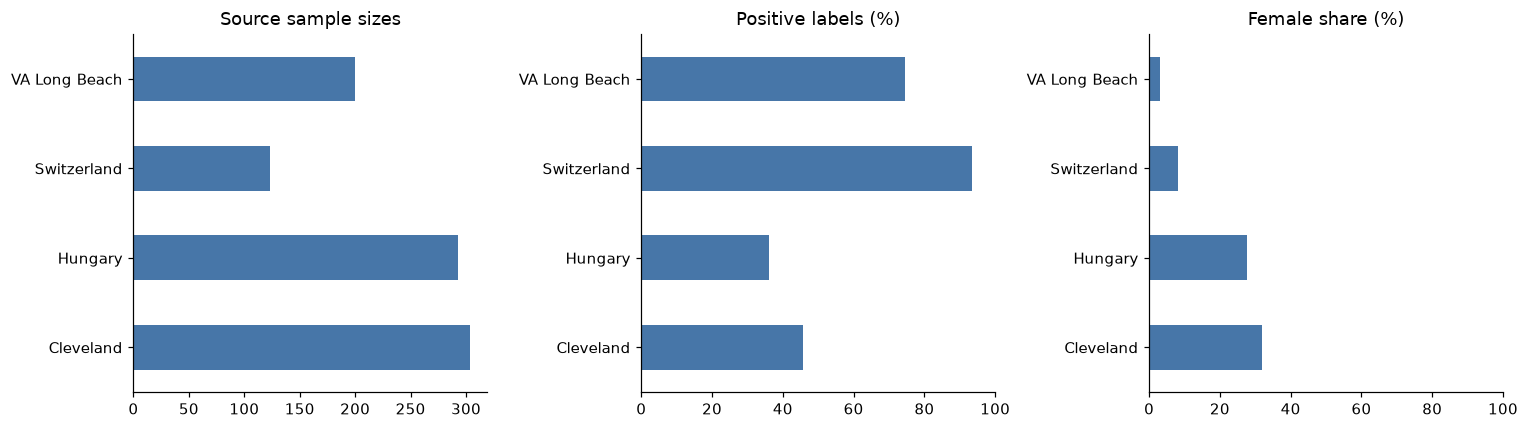

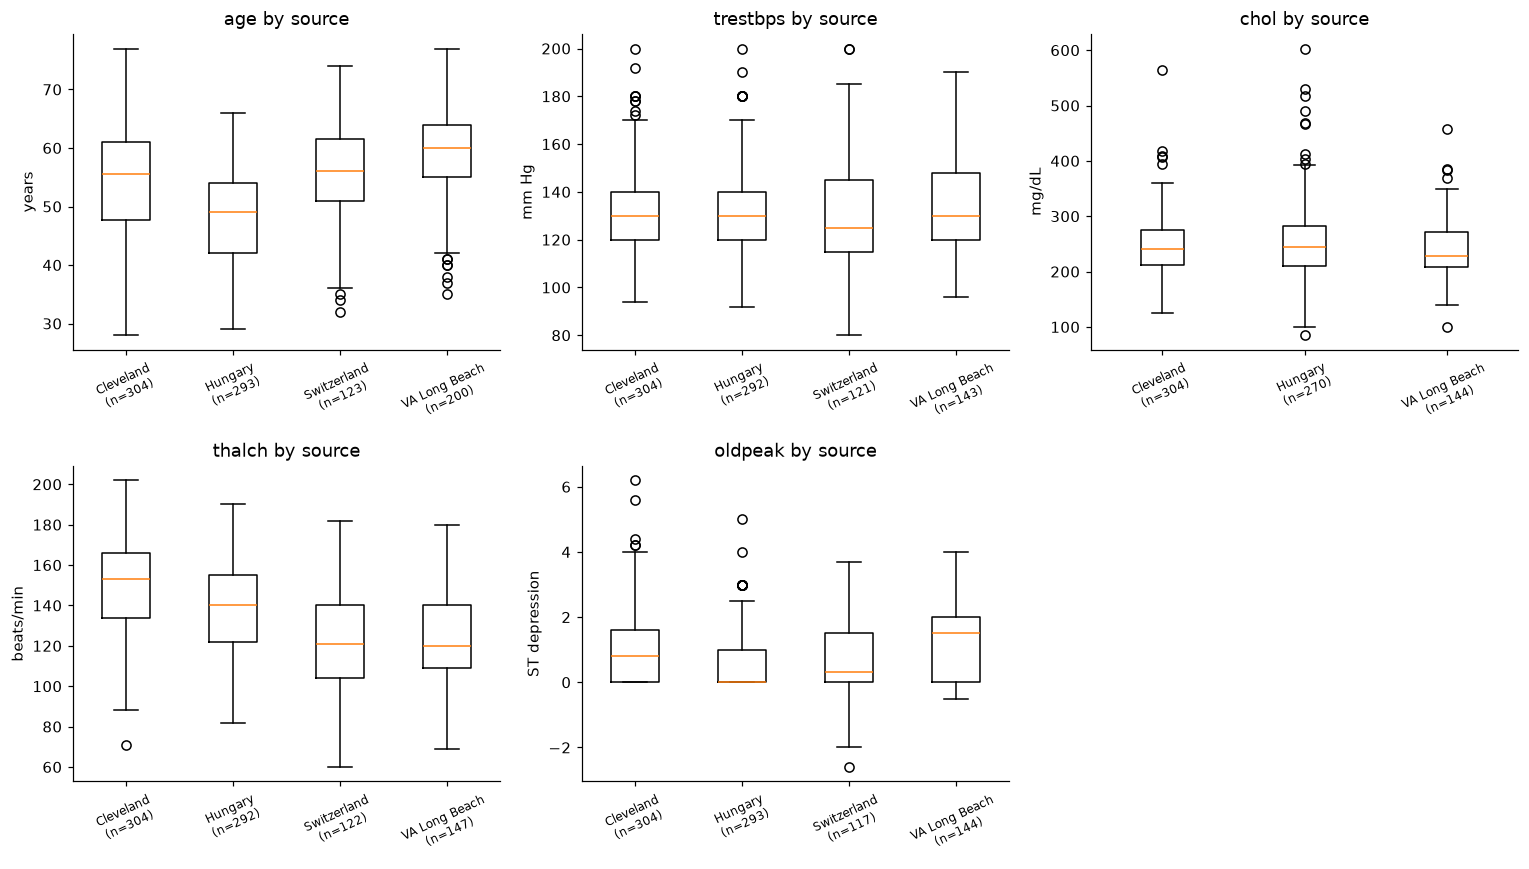

Sources with no usable cholesterol are absent from the cholesterol boxplot.


In [13]:
source_summary = analysis_df.groupby('dataset').agg(
    rows=('id', 'size'), valid_labels=('disease_present', 'count'),
    positive_labels=('disease_present', 'sum'), observed_sex=('sex', 'count'),
    female_rows=('sex', lambda s: s.eq('Female').sum()), age_median=('age', 'median'),
).reindex(SOURCES)
source_summary['share_of_dataset_pct'] = source_summary.rows.div(len(df)).mul(100)
source_summary['positive_pct_valid_labels'] = source_summary.positive_labels.div(source_summary.valid_labels).mul(100)
source_summary['female_pct_observed_sex'] = source_summary.female_rows.div(source_summary.observed_sex).mul(100)
source_summary['mean_unavailable_predictors'] = missing_per_row.groupby(analysis_df.dataset).mean().reindex(SOURCES)
complete = analysis_df[PREDICTORS].notna().all(axis=1)
source_summary['complete_rows'] = complete.groupby(analysis_df.dataset).sum().reindex(SOURCES)
source_summary['complete_pct'] = source_summary.complete_rows.div(source_summary.rows).mul(100)
display(source_summary)

source_numeric_rows = []
for source in SOURCES:
    subset = analysis_df.loc[analysis_df.dataset.eq(source)]
    for feature in CONTINUOUS:
        values = subset[feature].dropna()
        source_numeric_rows.append({'source': source, 'feature': feature, 'observed_n': len(values),
                                    'median': values.median(), 'q1': values.quantile(.25),
                                    'q3': values.quantile(.75), 'mean': values.mean()})
source_numeric = pd.DataFrame(source_numeric_rows)
display(source_numeric.set_index(['source', 'feature']))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, column, title in zip(axes, ['rows', 'positive_pct_valid_labels', 'female_pct_observed_sex'],
                              ['Source sample sizes', 'Positive labels (%)', 'Female share (%)']):
    source_summary[column].plot.barh(ax=ax, color='#4776a8')
    ax.set(title=title, ylabel='')
    if column != 'rows':
        ax.set_xlim(0, 100)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, feature in zip(axes.flat, CONTINUOUS):
    samples, labels = [], []
    for source in SOURCES:
        values = analysis_df.loc[analysis_df.dataset.eq(source), feature].dropna()
        if len(values):
            samples.append(values)
            labels.append(f'{source}\n(n={len(values)})')
    ax.boxplot(samples, tick_labels=labels, showfliers=True)
    ax.set(title=f'{feature} by source', ylabel=units[feature])
    ax.tick_params(axis='x', labelrotation=25, labelsize=8)
axes.flat[-1].set_visible(False)
fig.tight_layout()
plt.show()
print('Sources with no usable cholesterol are absent from the cholesterol boxplot.')


## 10. Distributions by target and exploratory associations

Normalized histograms compare shapes despite unequal class sizes. Associations are
descriptive: source and measurement availability can confound pooled comparisons.
Spearman correlations use pairwise available values; inspect the companion pair counts,
especially before interpreting relationships involving sparse features.


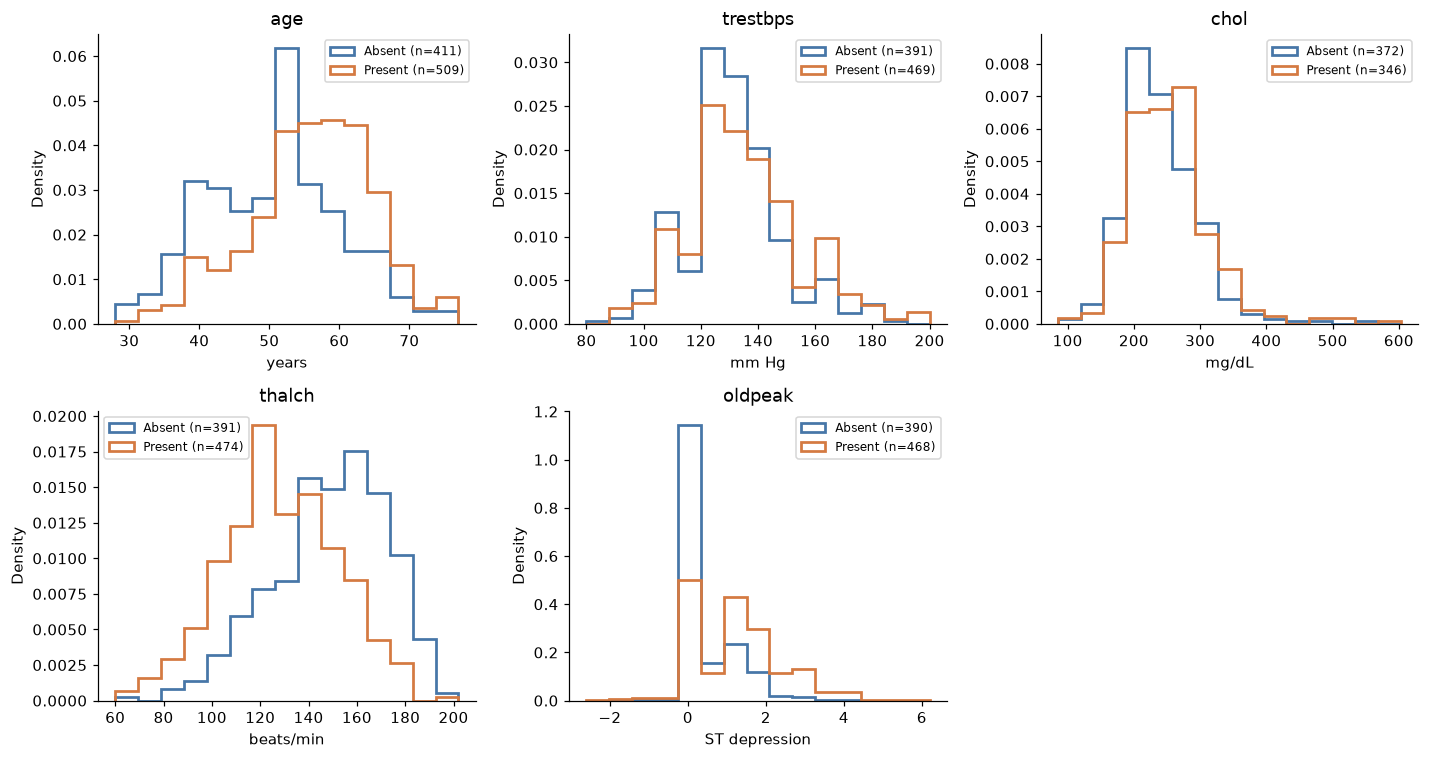

observed_n  median     q1      q3
feature  target                                    
age      Absent          411   51.00   43.0   57.00
         Present         509   57.00   51.0   62.00
trestbps Absent          391  130.00  120.0  140.00
         Present         469  130.00  120.0  145.00
chol     Absent          372  233.00  204.0  270.25
         Present         346  248.00  216.0  284.75
thalch   Absent          391  151.00  134.5  167.50
         Present         474  128.00  112.0  145.00
oldpeak  Absent          390    0.00    0.0    0.80
         Present         468    1.05    0.0    2.00

,age,trestbps,chol,thalch,oldpeak,ca
age,1.000,0.260,0.100,-0.348,0.288,0.391
trestbps,0.260,1.000,0.089,-0.089,0.163,0.071
chol,0.100,0.089,1.000,-0.033,0.074,0.147
thalch,-0.348,-0.089,-0.033,1.000,-0.188,-0.286
oldpeak,0.288,0.163,0.074,-0.188,1.000,0.254
ca,0.391,0.071,0.147,-0.286,0.254,1.000


**Observed record count for each pair**

,age,trestbps,chol,thalch,oldpeak,ca
age,920,860,718,865,858,309
trestbps,860,860,675,860,853,309
chol,718,675,718,676,674,302
thalch,865,860,676,865,857,309
oldpeak,858,853,674,857,858,309
ca,309,309,302,309,309,309


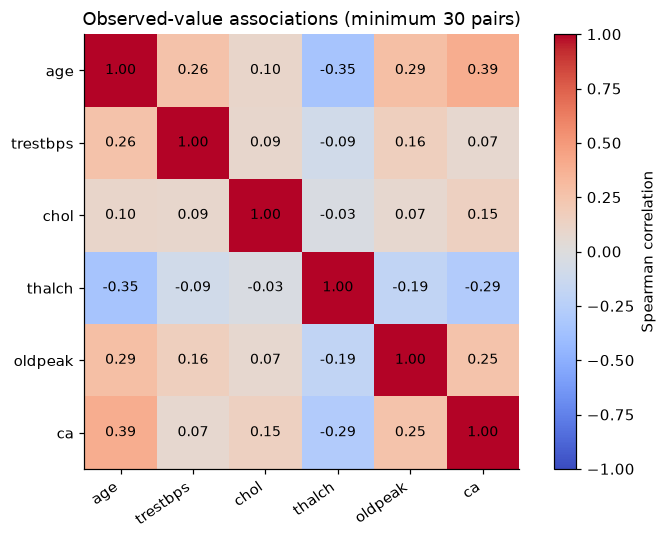

In [14]:
target_numeric_rows = []
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, feature in zip(axes.flat, CONTINUOUS):
    observed = analysis_df[feature].dropna()
    bins = np.histogram_bin_edges(observed, bins=15)
    for label, name, color in [(False, 'Absent', '#4776a8'), (True, 'Present', '#d47a42')]:
        values = analysis_df.loc[analysis_df.disease_present.eq(label).fillna(False), feature].dropna()
        target_numeric_rows.append({'target': name, 'feature': feature, 'observed_n': len(values),
                                    'median': values.median(), 'q1': values.quantile(.25),
                                    'q3': values.quantile(.75)})
        if len(values):
            ax.hist(values, bins=bins, density=True, histtype='step', linewidth=1.8,
                    label=f'{name} (n={len(values)})', color=color)
    ax.set(title=feature, xlabel=units[feature], ylabel='Density')
    ax.legend(fontsize=8)
axes.flat[-1].set_visible(False)
fig.tight_layout()
plt.show()
display(pd.DataFrame(target_numeric_rows).set_index(['feature', 'target']))

corr_features = [*CONTINUOUS, 'ca']
corr = analysis_df[corr_features].corr(method='spearman', min_periods=30)
observed = analysis_df[corr_features].notna().astype('int64')
pair_counts = observed.T.dot(observed)
display(corr)
display(Markdown('**Observed record count for each pair**'))
display(pair_counts)
fig, ax = plt.subplots(figsize=(7, 5))
heat = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_features)), corr_features, rotation=35, ha='right')
ax.set_yticks(range(len(corr_features)), corr_features)
for row in range(len(corr_features)):
    for col in range(len(corr_features)):
        ax.text(col, row, f'{corr.iloc[row, col]:.2f}', ha='center', va='center', fontsize=9)
fig.colorbar(heat, ax=ax, label='Spearman correlation')
ax.set_title('Observed-value associations (minimum 30 pairs)')
fig.tight_layout()
plt.show()


## 11. Findings and implications for the next stage

The summary below is calculated from the preceding cells so that rerunning the notebook
keeps its conclusions aligned with the input file.


In [15]:
source_rates = '; '.join(f'{source}: {row.positive_pct_valid_labels:.1f}% (n={int(row.rows)})'
                         for source, row in source_summary.iterrows())
sparse_fields = '; '.join(f'{feature}: {missing_summary.loc[feature, "raw_missing_n"]} '
                         f'({missing_summary.loc[feature, "raw_missing_pct"]:.1f}%)'
                         for feature in ['ca', 'thal', 'slope'])
chol_zero_n = int(df.chol.eq(0).sum())
bp_zero_n = int(df.trestbps.eq(0).sum())
complete_n = int(complete.sum())
non_domain_issues = sum(int(mask.fillna(False).sum()) for (column, rule), mask in flags.items()
                      if rule not in ['nonpositive value', 'missing required value'])
findings = f"""
- **Structure:** {len(df):,} records, {len(EXPECTED_COLUMNS)} columns, 13 candidate predictors,
  an ID, a source label, and the five-class target. CSV widths and headers passed inspection.
- **Malformed data:** {non_domain_issues} parse, category, finite-value, integer, or code violations;
  {chol_zero_n} zero cholesterol values and {bp_zero_n} zero resting-pressure values were separately
  flagged. Zero cholesterol occurs in {int(zero_by_source.loc['Switzerland', 'chol'])} of
  {int(source_summary.loc['Switzerland', 'rows'])} Swiss records and in
  {int(zero_by_source.loc['VA Long Beach', 'chol'])} VA Long Beach records.
- **Duplicates:** {int(raw.duplicated().sum())} literal duplicates, but
  {int(df.duplicated(record_columns).sum())} extra records after excluding ID
  ({len(duplicate_records)} rows across the matching groups). Review before splitting data;
  a unique ID does not establish an independent patient.
- **Missingness:** {sparse_fields}. Only {complete_n} records ({complete_n / len(df):.1%})
  have all 13 usable predictors. Complete-case deletion would substantially change the source mix.
- **Class balance:** {int(binary_counts.loc[True])} present ({binary_counts.loc[True]/binary_counts.sum():.1%})
  versus {int(binary_counts.loc[False])} absent ({binary_counts.loc[False]/binary_counts.sum():.1%}).
  Class 4 has only {int(class_counts.loc[4])} records; multiclass evaluation needs per-class support.
- **Source differences:** positive-label rates are {source_rates}. Compare these alongside
  source-specific missingness, sex composition, and numeric observed counts.
- **Outliers:** {len(outlier_records)} rows have a pooled continuous-variable IQR flag.
  Inspect their raw values and source before any treatment. The {int(df.oldpeak.lt(0).sum())}
  negative oldpeak values remain available for review.

**Next steps:** establish preprocessing rules for impossible measurements; investigate matching
records and the local CSV's provenance; decide how to handle sparse predictors using training
data only. Exclude ID from predictors and treat source as a grouping variable during evaluation.
Compare a stratified random split with a held-out-source evaluation, keep repeated profiles
together, and report results by source. Fit imputation and any outlier handling within training
folds. Retain the original target and document whether the first model is binary or multiclass.
"""
display(Markdown(findings))



- **Structure:** 920 records, 16 columns, 13 candidate predictors,
  an ID, a source label, and the five-class target. CSV widths and headers passed inspection.
- **Malformed data:** 0 parse, category, finite-value, integer, or code violations;
  172 zero cholesterol values and 1 zero resting-pressure values were separately
  flagged. Zero cholesterol occurs in 123 of
  123 Swiss records and in
  49 VA Long Beach records.
- **Duplicates:** 0 literal duplicates, but
  2 extra records after excluding ID
  (4 rows across the matching groups). Review before splitting data;
  a unique ID does not establish an independent patient.
- **Missingness:** ca: 611 (66.4%); thal: 486 (52.8%); slope: 309 (33.6%). Only 299 records (32.5%)
  have all 13 usable predictors. Complete-case deletion would substantially change the source mix.
- **Class balance:** 509 present (55.3%)
  versus 411 absent (44.7%).
  Class 4 has only 28 records; multiclass evaluation needs per-class support.
- **Source differences:** positive-label rates are Cleveland: 45.7% (n=304); Hungary: 36.2% (n=293); Switzerland: 93.5% (n=123); VA Long Beach: 74.5% (n=200). Compare these alongside
  source-specific missingness, sex composition, and numeric observed counts.
- **Outliers:** 64 rows have a pooled continuous-variable IQR flag.
  Inspect their raw values and source before any treatment. The 12
  negative oldpeak values remain available for review.

**Next steps:** establish preprocessing rules for impossible measurements; investigate matching
records and the local CSV's provenance; decide how to handle sparse predictors using training
data only. Exclude ID from predictors and treat source as a grouping variable during evaluation.
Compare a stratified random split with a held-out-source evaluation, keep repeated profiles
together, and report results by source. Fit imputation and any outlier handling within training
folds. Retain the original target and document whether the first model is binary or multiclass.


In [16]:
# Internal consistency checks for the audit, rather than fixed assumptions about row counts.
assert raw.shape == df.shape
assert raw.columns.tolist() == EXPECTED_COLUMNS
assert analysis_df.index.equals(raw.index)
assert int(class_counts.sum()) == int(target_valid.sum())
assert int(binary_counts.sum()) == int(target_valid.sum())
assert missing_summary.analysis_unavailable_n.ge(missing_summary.raw_missing_n).all()
assert analysis_df.chol.dropna().gt(0).all()
assert analysis_df.trestbps.dropna().gt(0).all()
assert source_classes.to_numpy().sum() == int(target_valid.sum())
assert hashlib.sha256(data_path.read_bytes()).hexdigest() == raw_sha256
print('Audit consistency checks passed. The notebook never writes the CSV.')


Audit consistency checks passed. The notebook never writes the CSV.
